In [1]:
import sys
import os

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, os.path.join(REPO_ROOT, 'code'))

import numpy as np
import pandas as pd

from scunit import ScUnit

# between-cluster signature testing

In [7]:
COSMIC_PATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/COSMIC/COSMIC_v3.4_SBS_GRCh38.txt'))
cosmic = pd.read_csv(COSMIC_PATH, sep = '\t').set_index('Type').T

breast_sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS9', 'SBS13', 'SBS17a', 'SBS17b', 'SBS18', 'SBS37', 'SBS40a', 'SBS40b', 'SBS40c', 'SBS41']

In [3]:
FILEPATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/SBS-count-by-cell/funnell2022single-SA1035.csv'))
Y = ScUnit(FILEPATH, min_mutations=50)

Loaded 2586 cells.
Mutations per cell:
	min:  54
	mean: 663
	max:  4610


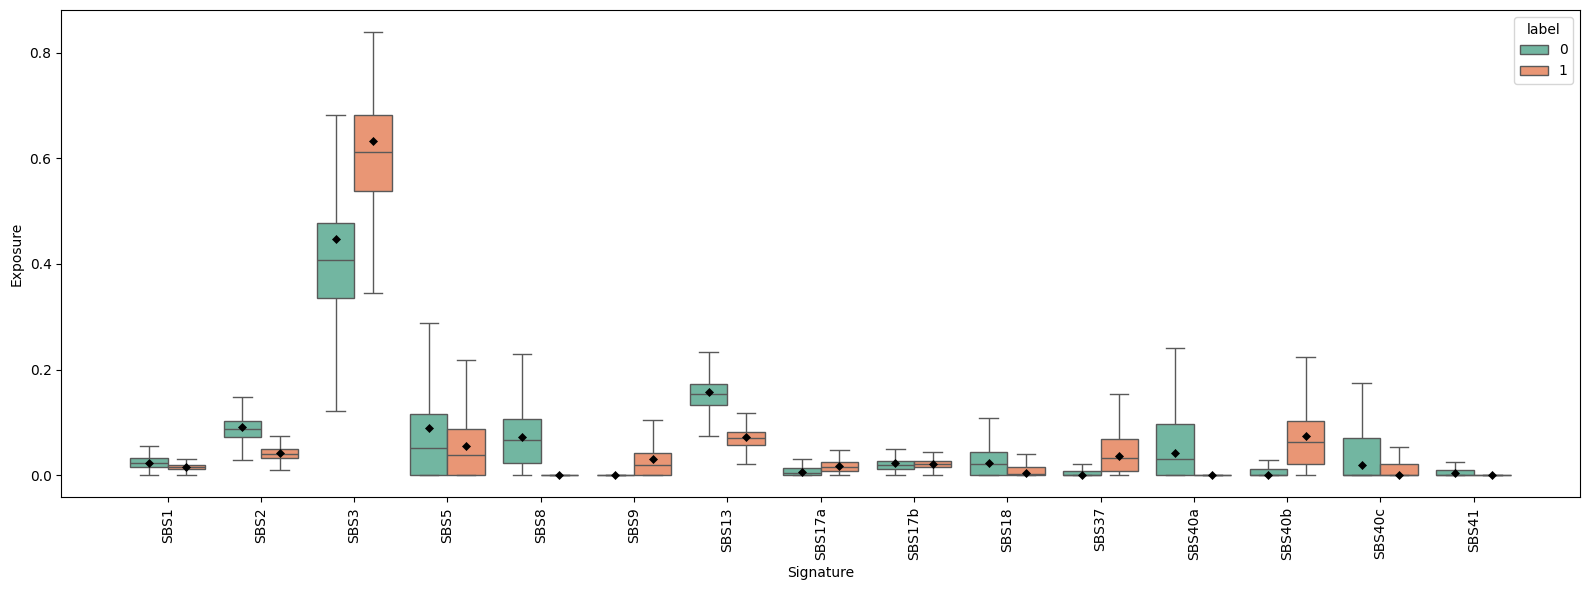

In [8]:
Y.umap().hdbscan().plot_exposures(signatures=cosmic.loc[breast_sigs].T)

In [ ]:
def clr(df_exposures, numerical_zero=1e-10):
    """
    Centered log-ratio (CLR) transformation of compositional exposure data.
    
    Zeros are replaced with a small epsilon (2/3 of the smallest non-zero value)
    prior to transformation to ensure numerical stability. Rows are re-normalized
    after zero replacement to maintain the unit-sum constraint.
    
    Parameters
    ----------
    df_exposures : pd.DataFrame
        Per-cell signature exposures (rows = cells, columns = signatures).
    numerical_zero : float
        Values below this threshold are treated as zero. Default is 1e-10.
    
    Returns
    -------
    pd.DataFrame
        CLR-transformed exposures.
    """
    df = df_exposures.copy()

    # replace near-zero values with epsilon to avoid log(0)
    epsilon = (2/3) * df[df > numerical_zero].min().min()
    df[df <= numerical_zero] = epsilon
    
    # re-normalize rows to maintain unit-sum constraint
    df = df.div(df.sum(axis=1), axis=0)
    
    # centered log-ratio transformation
    df = df.apply(lambda x: np.log(x / np.exp(np.log(x).mean())), axis=1)
    
    return df

def test_signature_exposures(df_exposures, labels, clr_transform=True, numerical_zero=1e-10):
    """
    Test for differential signature activity between clusters using Kruskal-Wallis test.
    
    Parameters
    ----------
    df_exposures : pd.DataFrame
        Per-cell signature exposures (rows = cells, columns = signatures).
    labels : pd.Series
        Cluster labels (e.g., from ScUnit.get_labels()). Noise points (-1) are excluded.
    clr_transform : bool
        If True, apply CLR transformation prior to testing. Default is True.
    numerical_zero : float
        Values below this threshold are treated as zero. Default is 1e-10.
    
    Returns
    -------
    pd.DataFrame
        DataFrame with columns 'stat', 'p_value', 'p_value_bh', and 'eta_squared'
        for each signature.
    """
    from scipy.stats import kruskal
    from statsmodels.stats.multitest import multipletests

    df = clr(df_exposures, numerical_zero=numerical_zero) if clr_transform else df_exposures.copy()

    mask = labels.values != -1
    df = df.loc[mask].reset_index(drop=True)
    labels_clean = labels.values[mask]
    unique_labels = np.unique(labels_clean)
    n = len(labels_clean)
    k = len(unique_labels)

    results = {}
    for sig in df.columns:
        groups = [df.loc[labels_clean == label, sig].values for label in unique_labels]
        stat, pval = kruskal(*groups)
        eta_sq = (stat - k + 1) / (n - k)
        results[sig] = {'stat': stat, 'p_value': pval, 'eta_squared': eta_sq}
    
    result_df = pd.DataFrame(results).T
    _, pvals_bh, _, _ = multipletests(result_df['p_value'], method='fdr_bh')
    result_df['p_value_bh'] = pvals_bh
    
    return result_df[['stat', 'eta_squared', 'p_value', 'p_value_bh']]

In [42]:
labels = Y.umap().hdbscan().get_labels()
exposures = Y.deconv(signatures=cosmic.loc[breast_sigs].T)

In [43]:
test_signature_exposures(exposures, labels)

H=1182.09, p=4.77e-259
eta_sq = 0.4571
cluster 0: n=1708, median=3.408
cluster 1: n=878, median=-6.932


,stat,eta_squared,p_value,p_value_bh
SBS1,35.091964,0.013193,3.144960e-09,3.369600e-09
SBS2,275.266029,0.106140,8.076838e-62,1.514407e-61
SBS3,152.347195,0.058571,5.320403e-35,7.980604e-35
SBS5,1.131608,0.000051,2.874325e-01,2.874325e-01
SBS8,1182.086333,0.457077,4.769392e-259,7.154088e-258
SBS9,761.918444,0.294473,1.027850e-167,3.854438e-167
SBS13,305.492108,0.117838,2.095374e-68,4.490088e-68
SBS17a,484.510886,0.187117,2.229433e-107,5.573581e-107
SBS17b,59.346628,0.022580,1.322065e-14,1.652582e-14
SBS18,185.009741,0.071211,3.905453e-42,6.509088e-42


In [17]:
exposures

,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a,SBS17b,SBS18,SBS37,SBS40a,SBS40b,SBS40c,SBS41
cell_id,,,,,,,,,,,,,,,
SA1035X4XB02879-A95626A-R03-C22,0.016505,0.116008,0.373652,0.079604,0.082105,0.001068,0.181576,0.001763,0.015147,0.000000,0.000000,0.089838,0.009843,0.000000,0.032892
SA1035X4XB02879-A95626A-R03-C24,0.030030,0.088916,0.485862,0.000000,0.075066,0.000000,0.169174,0.003695,0.013031,0.030635,0.000000,0.085833,0.000000,0.000000,0.017758
SA1035X4XB02879-A95626A-R03-C31,0.016706,0.124863,0.336249,0.096864,0.104948,0.000000,0.174069,0.009296,0.018417,0.011391,0.000000,0.026029,0.081168,0.000000,0.000000
SA1035X4XB02879-A95626A-R03-C37,0.028653,0.072179,0.399525,0.000000,0.069310,0.016530,0.142543,0.012628,0.030155,0.045306,0.000000,0.047861,0.000000,0.135309,0.000000
SA1035X4XB02879-A95626A-R03-C44,0.017512,0.099452,0.507809,0.000000,0.062098,0.000000,0.157935,0.013389,0.006729,0.046243,0.000000,0.083432,0.000000,0.005402,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SA1035X8XB03631-A98256A-R25-C26,0.026757,0.073266,0.355506,0.232414,0.046439,0.009061,0.142548,0.031917,0.006209,0.000000,0.000000,0.000000,0.000000,0.062635,0.013249
SA1035X8XB03631-A98256A-R25-C31,0.059315,0.078661,0.404411,0.160225,0.038347,0.000000,0.098718,0.029894,0.021143,0.079777,0.000000,0.000000,0.000000,0.029510,0.000000
SA1035X8XB03631-A98256A-R25-C37,0.035244,0.066720,0.582585,0.000000,0.000000,0.000000,0.130565,0.000000,0.019365,0.039812,0.000000,0.034498,0.000000,0.091210,0.000000


In [21]:
exposures


,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a,SBS17b,SBS18,SBS37,SBS40a,SBS40b,SBS40c,SBS41
cell_id,,,,,,,,,,,,,,,
SA1035X4XB02879-A95626A-R03-C22,1.435212,3.385228,4.554894,3.008633,3.039563,-1.302247,3.833243,-0.801604,1.349389,-8.225014,-8.225014,3.129572,0.918363,-8.225014,2.124795
SA1035X4XB02879-A95626A-R03-C24,3.144348,4.229827,5.928064,-7.114443,4.060504,-7.114443,4.873066,1.049083,2.309493,3.164294,-7.114443,4.194542,-7.114443,-7.114443,2.618995
SA1035X4XB02879-A95626A-R03-C31,1.772276,3.783744,4.774378,3.529834,3.609986,-7.900058,4.115978,1.186095,1.869783,1.389375,-7.900058,2.215743,3.353040,-7.900058,-7.900058
SA1035X4XB02879-A95626A-R03-C37,2.239702,3.163593,4.874721,-7.972139,3.123034,1.689605,3.844089,1.420374,2.290810,2.697878,-7.972139,2.752746,-7.972139,3.792005,-7.972139
SA1035X4XB02879-A95626A-R03-C44,2.659814,4.396593,6.027027,-7.059661,3.925635,-7.059661,4.859107,2.391332,1.703338,3.630823,-7.059661,4.220950,-7.059661,1.483688,-7.059661
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SA1035X8XB03631-A98256A-R25-C26,2.320888,3.328172,4.907620,4.482599,2.872209,1.238079,3.993754,2.497212,0.860126,-7.822505,-7.822505,-7.822505,-7.822505,3.171394,1.617966
SA1035X8XB03631-A98256A-R25-C31,3.569802,3.852078,5.489369,4.563517,3.133611,-7.369646,4.079200,2.884608,2.538226,3.866167,-7.369646,-7.369646,-7.369646,2.871652,-7.369646
SA1035X8XB03631-A98256A-R25-C37,4.515123,5.153317,7.320290,-5.903769,-5.903769,-5.903769,5.824686,-5.903769,3.916279,4.636995,-5.903769,4.493717,-5.903769,5.465974,-5.903769
